Saving diabetes_binary_5050split_health_indicators_BRFSS2015.csv to diabetes_binary_5050split_health_indicators_BRFSS2015 (1).csv
Dataset loaded successfully!
Dataset Shape: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth           

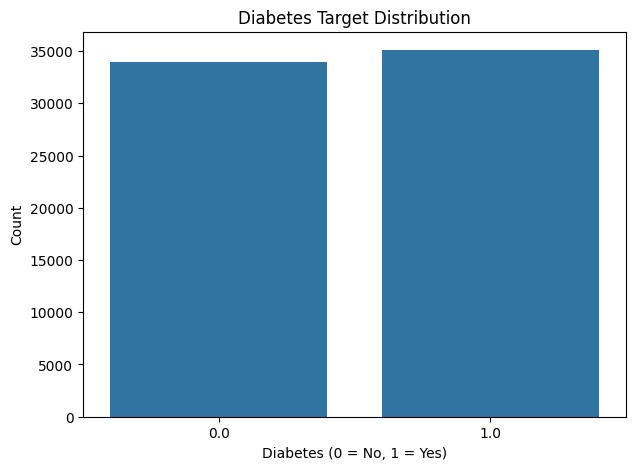

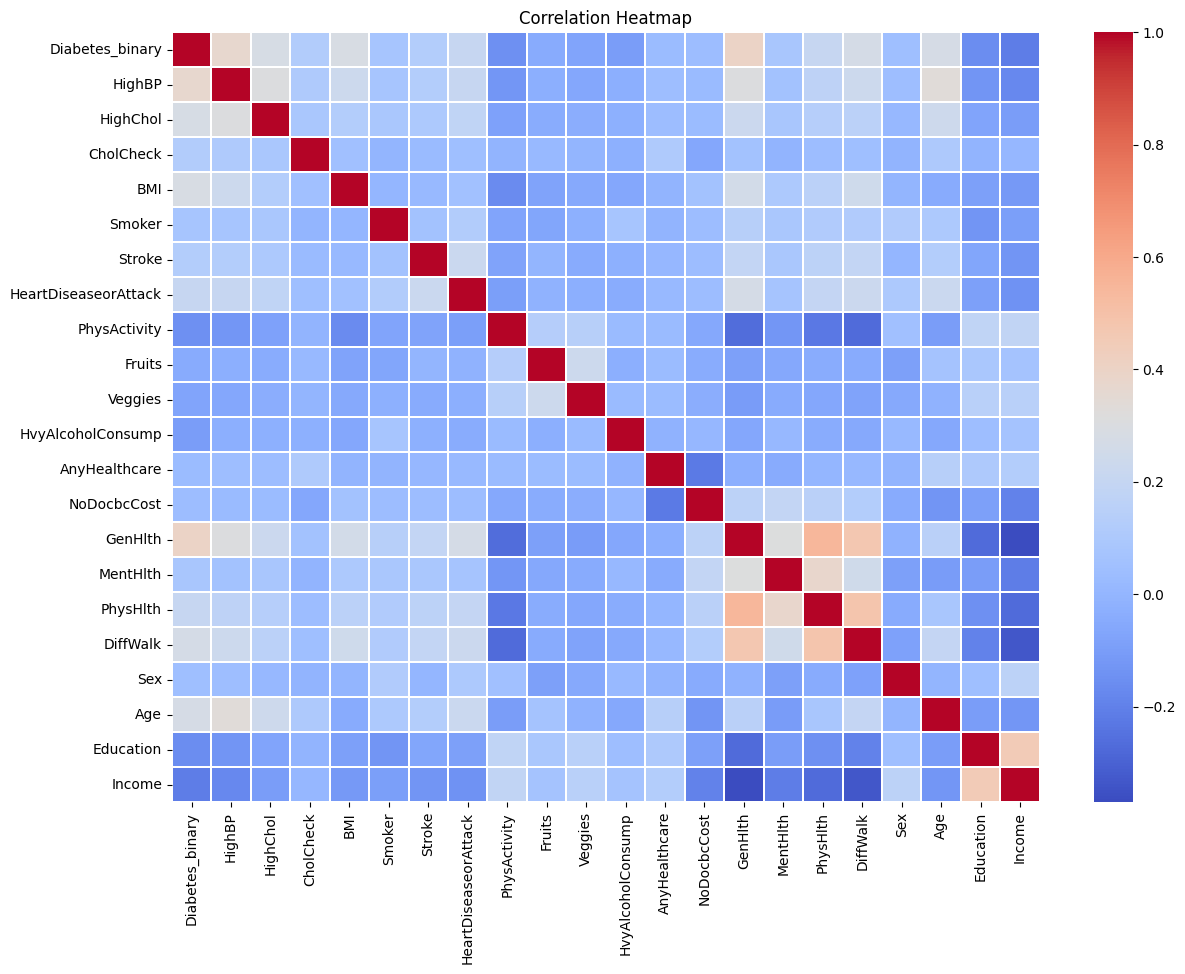

In [8]:

# 1. Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

# 2. Upload Dataset
uploaded = files.upload()

# Get the uploaded CSV filename
file_name = next(iter(uploaded))

# 3. Load Dataset
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")

# 4. Check Dataset Shape and Information
print("Dataset Shape:", df.shape)

display(df.head())

df.info()

# 5. Check and Remove Duplicate Rows
print("Duplicates before:", df.duplicated().sum())

df = df.drop_duplicates()

print("Duplicates after:", df.duplicated().sum())

# 6. Check Missing Values
print("Missing Values:\n", df.isnull().sum())

print("Total Missing Values:", df.isnull().sum().sum())

# 7. Plot Target Distribution
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x='Diabetes_binary')

plt.title('Diabetes Target Distribution')
plt.xlabel('Diabetes (0 = No, 1 = Yes)')
plt.ylabel('Count')

plt.show()

# 8. Plot Correlation Heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    df.corr(),
    cmap='coolwarm',
    annot=False,
    linewidths=0.3
)

plt.title('Correlation Heatmap')
plt.show()


# Stage 2: Data Splitting

The dataset was divided into three subsets:

- Training Set (70%)
- Validation Set (15%)
- Test Set (15%)

This splitting strategy was selected to provide sufficient data for training while maintaining reliable validation and testing performance.

In [9]:
from sklearn.model_selection import train_test_split

# Features and target
X = df.drop('Diabetes_binary', axis=1)
y = df['Diabetes_binary']

# 70% Train, 30% Temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# 15% Validation, 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training Set:", X_train.shape)
print("Validation Set:", X_val.shape)
print("Test Set:", X_test.shape)

Training Set: (48339, 21)
Validation Set: (10359, 21)
Test Set: (10359, 21)


# Stage 3: Model Selection and Development

## Selected Models

Three machine learning models were selected for diabetes prediction:

1. Logistic Regression
2. Random Forest
3. Neural Network (MLP)

These models were selected to compare traditional machine learning methods with a neural network model and determine the most effective approach for diabetes prediction.

### Logistic Regression
Logistic Regression was selected because it is a simple and efficient algorithm for binary classification problems.

### Random Forest
Random Forest was selected because it can handle complex relationships between features and reduce overfitting.

### Neural Network
Neural Network (MLP) was selected because it can learn complex patterns and nonlinear relationships within the dataset.

In [10]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Scaling completed successfully!")

Scaling completed successfully!


In [11]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

logistic_model = LogisticRegression(random_state=42)

random_forest_model = RandomForestClassifier(random_state=42)

neural_network_model = MLPClassifier(random_state=42)

print("Models initialized successfully!")

Models initialized successfully!


# Stage 4: Model Training and Hyperparameter Optimization
We tune all three models using cross-validation on the training set. Validation data is used to check generalization. Test data is not used until Stage 5.


In [5]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.base import clone
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
searches = {
    'Logistic Regression': GridSearchCV(LogisticRegression(max_iter=1500, random_state=42), {'C': [0.1, 1, 10]}, scoring='f1', cv=cv, n_jobs=-1),
    'Random Forest': GridSearchCV(RandomForestClassifier(random_state=42, n_jobs=-1), {'n_estimators': [100, 200], 'max_depth': [10, 20], 'min_samples_leaf': [1, 3]}, scoring='f1', cv=cv, n_jobs=-1),
    'Neural Network (MLP)': GridSearchCV(MLPClassifier(max_iter=120, early_stopping=True, n_iter_no_change=10, random_state=42), {'hidden_layer_sizes': [(32,), (64, 32)], 'alpha': [0.0001, 0.01], 'learning_rate_init': [0.001]}, scoring='f1', cv=cv, n_jobs=-1)
}
trained = {}
for name, search in searches.items():
    data = X_train if name == 'Random Forest' else X_train_scaled
    valid = X_val if name == 'Random Forest' else X_val_scaled
    print('Tuning:', name)
    search.fit(data, y_train)
    trained[name] = search.best_estimator_
    print('Best parameters:', search.best_params_)
    print('CV F1:', round(search.best_score_, 4))
    print('Train F1:', round(f1_score(y_train, search.predict(data)), 4))
    print('Validation F1:', round(f1_score(y_val, search.predict(valid)), 4))
    print()


Tuning: Logistic Regression
Best parameters: {'C': 0.1}
CV F1: 0.7539
Train F1: 0.7548
Validation F1: 0.7525

Tuning: Random Forest
Best parameters: {'max_depth': 10, 'min_samples_leaf': 3, 'n_estimators': 100}
CV F1: 0.7611
Train F1: 0.782
Validation F1: 0.7622

Tuning: Neural Network (MLP)
Best parameters: {'alpha': 0.01, 'hidden_layer_sizes': (64, 32), 'learning_rate_init': 0.001}
CV F1: 0.7654
Train F1: 0.7769
Validation F1: 0.7642



## Neural Network training and validation curves
The following separately trains a neural network with the selected hyperparameters for up to 100 epochs and records performance on the fixed validation set. The final model for testing remains the tuned model from cross-validation.


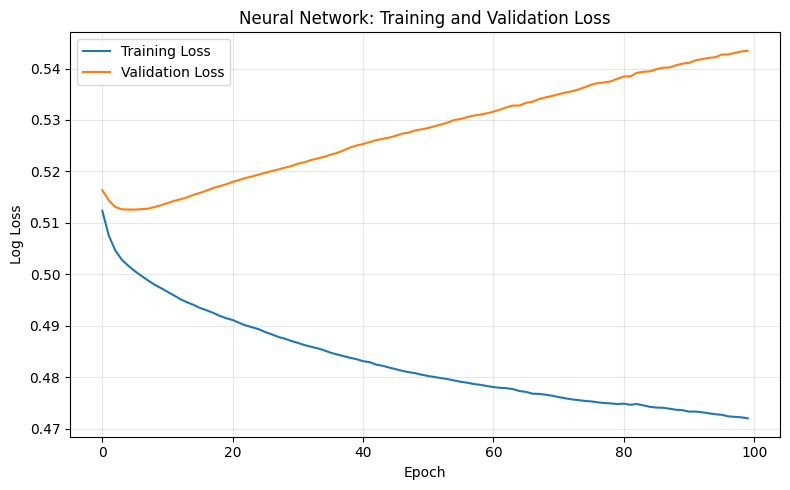

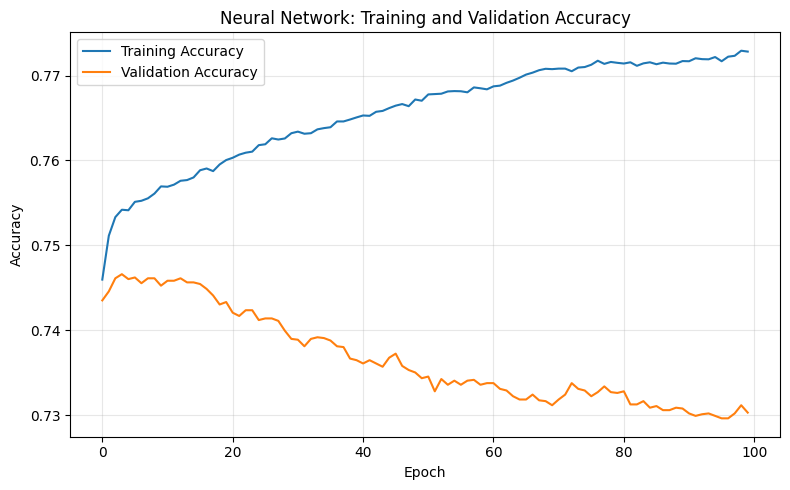

Final training loss: 0.472 Final validation loss: 0.5435


In [12]:
from sklearn.metrics import log_loss
best_mlp_params = searches['Neural Network (MLP)'].best_params_
curve_mlp = MLPClassifier(**best_mlp_params, max_iter=1, warm_start=True, early_stopping=False, random_state=42)
train_loss, val_loss, train_acc, val_acc = [], [], [], []
for epoch in range(100):
    curve_mlp.fit(X_train_scaled, y_train)
    train_loss.append(log_loss(y_train, curve_mlp.predict_proba(X_train_scaled), labels=[0, 1]))
    val_loss.append(log_loss(y_val, curve_mlp.predict_proba(X_val_scaled), labels=[0, 1]))
    train_acc.append(accuracy_score(y_train, curve_mlp.predict(X_train_scaled)))
    val_acc.append(accuracy_score(y_val, curve_mlp.predict(X_val_scaled)))

plt.figure(figsize=(8, 5))
plt.plot(train_loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.xlabel('Epoch'); plt.ylabel('Log Loss'); plt.title('Neural Network: Training and Validation Loss')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('neural_network_loss.png', dpi=180); plt.show()
plt.figure(figsize=(8, 5))
plt.plot(train_acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.title('Neural Network: Training and Validation Accuracy')
plt.legend(); plt.grid(alpha=.3); plt.tight_layout()
plt.savefig('neural_network_accuracy.png', dpi=180); plt.show()
print('Final training loss:', round(train_loss[-1], 4), 'Final validation loss:', round(val_loss[-1], 4))


# Stage 5: Model Final Evaluation and Comparison
Only now do we evaluate the selected models on the held-out test set. Recall and F1 are important because missing a positive diabetes case matters, while precision shows the proportion of positive predictions that are correct.



 Logistic Regression
              precision    recall  f1-score   support

         0.0       0.76      0.72      0.74      5094
         1.0       0.74      0.77      0.76      5265

    accuracy                           0.75     10359
   macro avg       0.75      0.75      0.75     10359
weighted avg       0.75      0.75      0.75     10359



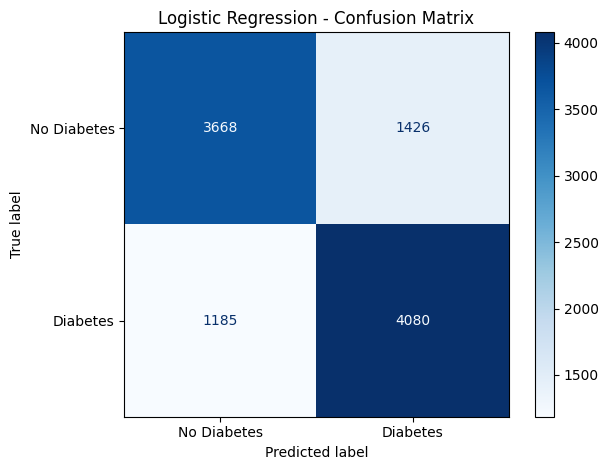


 Random Forest
              precision    recall  f1-score   support

         0.0       0.77      0.69      0.73      5094
         1.0       0.73      0.80      0.76      5265

    accuracy                           0.75     10359
   macro avg       0.75      0.74      0.74     10359
weighted avg       0.75      0.75      0.74     10359



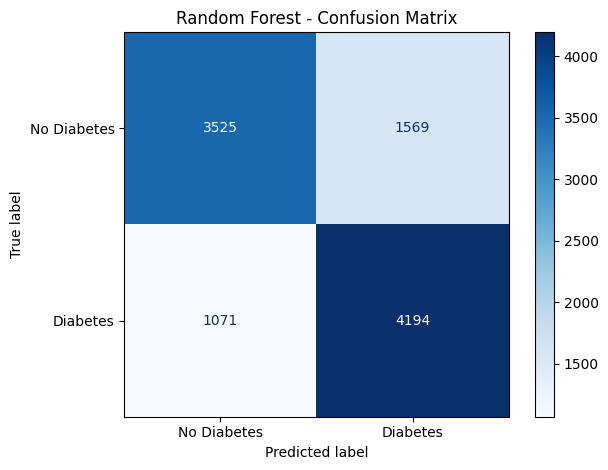


 Neural Network (MLP)
              precision    recall  f1-score   support

         0.0       0.79      0.67      0.73      5094
         1.0       0.72      0.83      0.77      5265

    accuracy                           0.75     10359
   macro avg       0.76      0.75      0.75     10359
weighted avg       0.76      0.75      0.75     10359



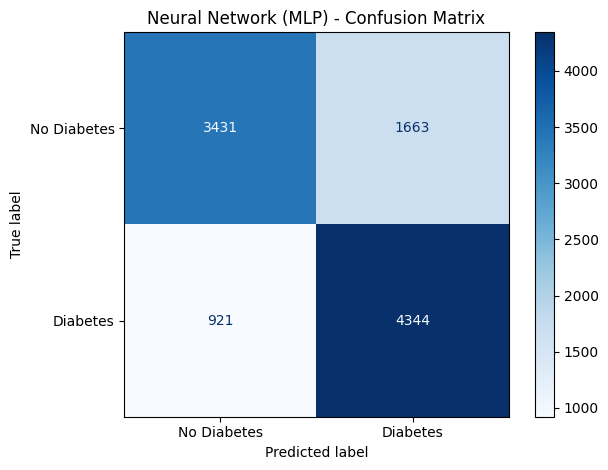

Final Test Results:


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
2,Neural Network (MLP),0.7506,0.7232,0.8251,0.7708,0.8228
1,Random Forest,0.7451,0.7277,0.7966,0.7606,0.8211
0,Logistic Regression,0.7479,0.7410,0.7749,0.7576,0.8179


Highest test F1-score: Neural Network (MLP)
Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


In [7]:
from sklearn.metrics import precision_score, recall_score, confusion_matrix, ConfusionMatrixDisplay, roc_auc_score, classification_report
rows = []
for name, model in trained.items():
    data = X_test if name == 'Random Forest' else X_test_scaled
    pred = model.predict(data)
    prob = model.predict_proba(data)[:, 1]
    rows.append({'Model': name, 'Accuracy': accuracy_score(y_test, pred), 'Precision': precision_score(y_test, pred, zero_division=0), 'Recall': recall_score(y_test, pred, zero_division=0), 'F1-score': f1_score(y_test, pred, zero_division=0), 'ROC-AUC': roc_auc_score(y_test, prob)})
    print('\n', name)
    print(classification_report(y_test, pred, zero_division=0))
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=['No Diabetes', 'Diabetes'], cmap='Blues')
    plt.title(name + ' - Confusion Matrix'); plt.tight_layout()
    plt.savefig(name.replace(' ', '_').replace('(', '').replace(')', '') + '_confusion_matrix.png', dpi=180)
    plt.show()
comparison = pd.DataFrame(rows).sort_values('F1-score', ascending=False)
print('Final Test Results:')
display(comparison.round(4))
comparison.to_csv('stage5_model_comparison.csv', index=False)
print('Highest test F1-score:', comparison.iloc[0]['Model'])


## Reporting instructions
1. Copy the printed best hyperparameters, cross-validation F1, training F1 and validation F1 into Stage 4 of the report.
2. Add the two saved neural-network curves, explain whether training and validation diverge, and mention how early stopping and tuning were used.
3. Copy the actual test metrics and confusion matrices into Stage 5. Identify the best model using F1 and recall together, rather than accuracy alone.
4. Do not use the test results to retune hyperparameters.
